# 02 - Exploratory data analysis

## Goal of this notebook, in simple terms

Before building any model, we look at the data with our own eyes and answer:

1. **How does the claim frequency change with each rating factor?** (e.g. do young drivers really
   have more accidents? how much more?)
2. **How does the average cost of a claim change with each factor?**
3. **Are some factors telling the same story?** (correlated factors can confuse a model and its
   interpretation)

The answers guide the modelling choices of notebooks 03-04: which variables to use, which need a
non-linear treatment (bins) in the GLM, and what we expect the models to find. They are also a
sanity check: if a model later says something completely different, we must understand why.

### Method: one-way analysis
A **one-way analysis** looks at one factor at a time. For each level $k$ of a factor
(e.g. driver age 18-20) we compute the **observed frequency**

$$\hat\lambda_k = \frac{\sum_{i \in k} N_i}{\sum_{i \in k} E_i} = \frac{\text{claims in the group}}{\text{exposure (policy-years) in the group}}$$

Note that this is *not* the average of the individual `ClaimNb/Exposure` ratios: it is a ratio of
sums, which automatically gives each policy a weight equal to its exposure (a 1-month policy with
a claim would otherwise count as a frequency of 12!).

**Uncertainty.** If claims in a group follow a Poisson distribution, the variance of the number of
claims equals its mean, so the standard error of $\hat\lambda_k$ is $\sqrt{N_k}/E_k$. We show a 95%
confidence interval $\hat\lambda_k \pm 1.96\,\sqrt{N_k}/E_k$: a wide band means "few data, do not
over-interpret this level".

**Limitation (important).** One-way results mix the effect of the factor with the effect of every
factor correlated with it. Example: young drivers also tend to have a high bonus-malus. The
one-way curve of age therefore *also* contains part of the bonus-malus effect. Disentangling
them is exactly what the multivariate models (GLM, GBM) do.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from motor_pricing.data import load_processed
from motor_pricing.eda import one_way_frequency, one_way_severity, cramers_v
from motor_pricing.plotting import set_style, save, SERIES, INK_2, GRID

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

df = load_processed()
PORTFOLIO_FREQ = df["ClaimNb"].sum() / df["Exposure"].sum()
claims_df = df[df["ClaimNb"] > 0]
PORTFOLIO_SEV = claims_df["ClaimAmountCapped"].sum() / claims_df["ClaimNb"].sum()
print(f"policies: {len(df):,}   portfolio frequency: {PORTFOLIO_FREQ:.4f}   average capped claim: {PORTFOLIO_SEV:,.0f} EUR")

policies: 678,013   portfolio frequency: 0.0737   average capped claim: 1,867 EUR


### Plotting helper
Each one-way chart has two panels sharing the x-axis:
* **top** - observed frequency (line) with its 95% confidence band and the portfolio average (dashed);
* **bottom** - how much exposure sits in each level (how much data supports each point).

In [2]:
def plot_one_way(table, title, value="frequency", portfolio=PORTFOLIO_FREQ, weight="exposure",
                 ylabel="claims per policy-year", name=None, rotate=False):
    x = np.arange(len(table))
    labels = [str(i) for i in table.index]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True,
                                   gridspec_kw={"height_ratios": [3, 1.2], "hspace": 0.08})
    ax1.fill_between(x, table["ci_low"], table["ci_high"], color=SERIES[0], alpha=0.15, lw=0)
    ax1.plot(x, table[value], color=SERIES[0], marker="o", ms=4)
    ax1.axhline(portfolio, color=INK_2, ls="--", lw=1)
    ax1.text(x[-1], portfolio, " portfolio", va="bottom", ha="right", color=INK_2, fontsize=9)
    ax1.set(title=title, ylabel=ylabel)
    ax2.bar(x, table[weight], color=GRID, edgecolor=INK_2, lw=0.3)
    ax2.set_ylabel(weight)
    step = max(1, len(x) // 25)
    ax2.set_xticks(x[::step]); ax2.set_xticklabels(labels[::step], rotation=90 if rotate else 0)
    if name:
        save(fig, name)
    plt.show()

## 1. Claim frequency by rating factor

**Goal of this step:** for each factor, see whether and how strongly the frequency moves, and
whether the relation is linear, monotone, U-shaped... This tells us how to encode the factor in
the GLM (a GLM on the log scale is linear unless we help it with bins).

### 1.1 Driver age

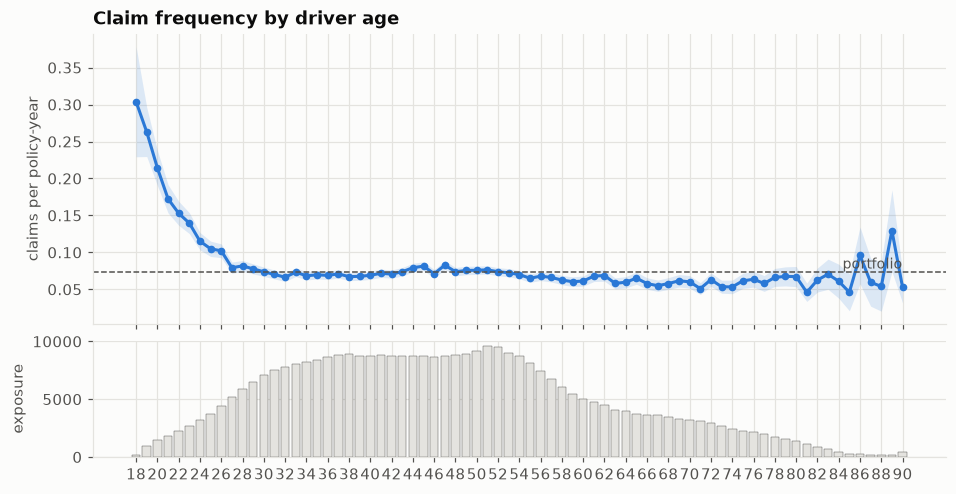

,exposure,claims,frequency,relative_to_portfolio
DrivAge (90 = 90+),,,,
18,210.6894,64,0.3038,4.1226
19,912.8743,240,0.2629,3.5681
20,"1,460.9792",313,0.2142,2.9076
25,"3,738.3022",392,0.1049,1.4231
30,"7,129.8654",526,0.0738,1.0012
40,"8,707.1160",601,0.0690,0.9368
50,"9,161.7301",695,0.0759,1.0295
60,"4,981.2877",305,0.0612,0.8310
70,"3,224.9944",194,0.0602,0.8164


In [3]:
t = one_way_frequency(df, df["DrivAge"].clip(upper=90).rename("DrivAge (90 = 90+)"))
plot_one_way(t, "Claim frequency by driver age", name="02_freq_drivage")
t.loc[[18, 19, 20, 25, 30, 40, 50, 60, 70, 80, 90], ["exposure", "claims", "frequency", "relative_to_portfolio"]]

**What we see**

* A very strong **decreasing curve for young drivers**: an 18-year-old has an observed frequency of
  ~0.30 claims per year, **about 4 times the portfolio average** (0.074); at 20 it is still ~2.9×,
  at 25 ~1.4×. From about 28 years on, the frequency is close to the average.
* A slight **bump around 45-55**: a known pattern in motor data, usually explained by teenage
  children driving their parents' car (the young driver is not the declared one).
* A slow decline after 55, then **noisy values above ~80** (very little exposure: wide bands).

**Mathematical meaning.** The relation is strongly *non-linear* and not monotone: a single linear
term $\beta\cdot\text{DrivAge}$ on the log scale cannot reproduce it. For the GLM we will cut age into
bins (18-20, 21-25, 26-30, 31-40, 41-50, 51-70, 71+), letting each bin have its own level.
The tree model will find the shape by itself.

**Real-world meaning.** Inexperience is the single biggest behavioural driver of accidents. Any
tariff that does not load young drivers heavily will be under-priced for them (and over-priced for
everybody else), attracting exactly the riskiest drivers from competitors - *adverse selection*.

### 1.2 Bonus-malus

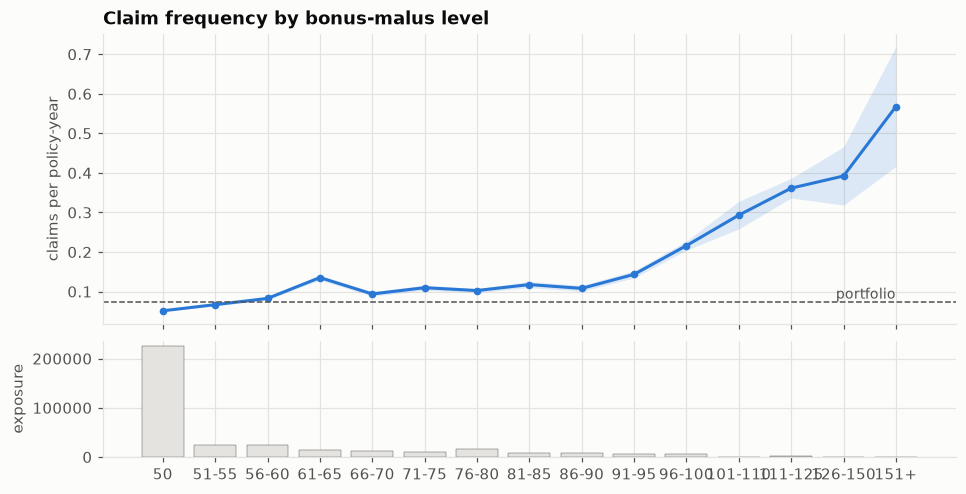

,exposure_share,claims,frequency,relative_to_portfolio
BonusMalus,,,,
50,0.6283,11553,0.0513,0.6964
51-55,0.0685,1640,0.0669,0.9073
56-60,0.0654,1936,0.0826,1.1215
61-65,0.0424,2055,0.1353,1.8364
66-70,0.0315,1061,0.0939,1.2746
71-75,0.0290,1140,0.1097,1.4894
76-80,0.0451,1658,0.1025,1.3918
81-85,0.0212,895,0.1177,1.5967
86-90,0.0213,825,0.1080,1.4663


In [4]:
bm_bins = pd.cut(df["BonusMalus"], [49, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100, 110, 125, 150, 250],
                 labels=["50", "51-55", "56-60", "61-65", "66-70", "71-75", "76-80", "81-85", "86-90",
                         "91-95", "96-100", "101-110", "111-125", "126-150", "151+"]).rename("BonusMalus")
t = one_way_frequency(df, bm_bins)
plot_one_way(t, "Claim frequency by bonus-malus level", name="02_freq_bonusmalus")
t[["exposure_share", "claims", "frequency", "relative_to_portfolio"]]

**What we see**

* 63% of the exposure sits at the floor level **BM = 50** (maximum bonus, at least ~13 claim-free
  years): these drivers have the lowest frequency, **0.70×** the portfolio average.
* Frequency then rises with the coefficient, reaching ~2.9× at 96-100 and **4-8× above 100** (malus).
  The increase is not perfectly smooth (a bump at 61-65): levels mix drivers of very different ages
  and histories (see section 3.1).

**Mathematical meaning.** Overall the frequency grows roughly *exponentially* with BM, i.e. roughly
**linearly on the log scale** - which is exactly what a log-link GLM with a linear term
$\beta\cdot\text{BM}$ can represent. We cap BM at 150 for the GLM, because above that there is
almost no exposure (0.03%) and the linear extrapolation would become extreme.

**Real-world meaning.** The bonus-malus is a summary of *past claims*, and past claims are the best
predictor of future claims (some drivers are intrinsically riskier in ways no factor captures:
the BM partially reveals this hidden risk). Note it is not independent of the target: the claims
of the current year will raise next year's BM - but within our one-year snapshot it is a legitimate
*a priori* rating factor.

### 1.3 Vehicle age and vehicle power

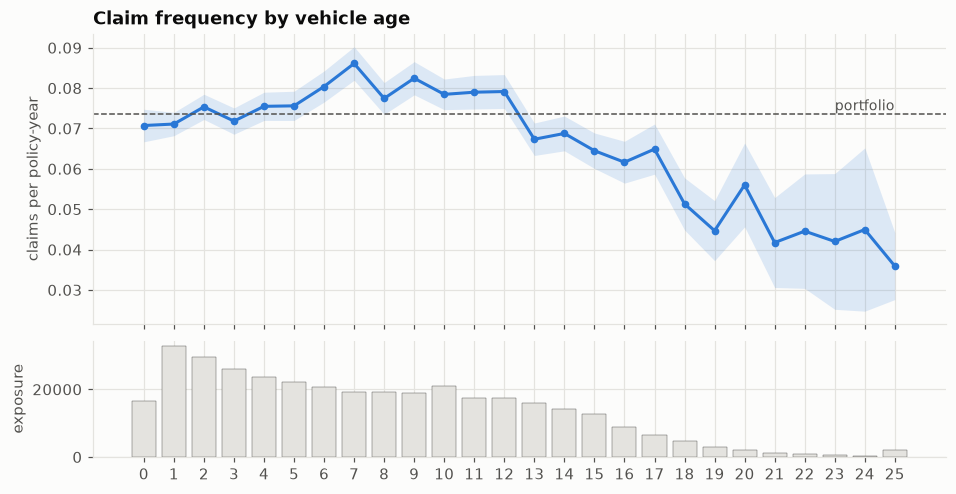

,exposure_share,frequency,relative_to_portfolio
VehAge (25 = 25+),,,
0,0.0466,0.0707,0.9600
1,0.0914,0.0711,0.9650
2,0.0829,0.0754,1.0227
5,0.0619,0.0756,1.0261
10,0.0584,0.0785,1.0647
15,0.0358,0.0645,0.8753
20,0.0056,0.0560,0.7603
25,0.0056,0.0359,0.4875


In [5]:
t = one_way_frequency(df, df["VehAge"].clip(upper=25).rename("VehAge (25 = 25+)"))
plot_one_way(t, "Claim frequency by vehicle age", name="02_freq_vehage")
t.loc[[0, 1, 2, 5, 10, 15, 20, 25], ["exposure_share", "frequency", "relative_to_portfolio"]]

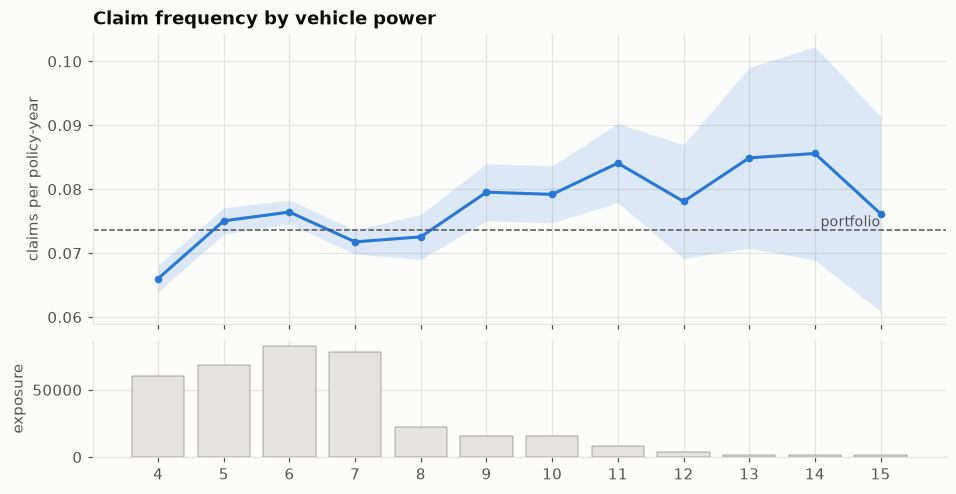

,exposure_share,frequency,relative_to_portfolio
VehPower,,,
4,0.1676,0.0660,0.8960
5,0.1902,0.0751,1.0187
6,0.2302,0.0764,1.0372
7,0.2174,0.0718,0.9740
8,0.0633,0.0726,0.9846
9,0.0428,0.0795,1.0795
10,0.0429,0.0792,1.0748
11,0.0237,0.0841,1.1412
12,0.0106,0.0781,1.0597


In [6]:
t = one_way_frequency(df, df["VehPower"])
plot_one_way(t, "Claim frequency by vehicle power", name="02_freq_vehpower")
t[["exposure_share", "frequency", "relative_to_portfolio"]]

**What we see**

* **Vehicle age**: almost flat (0.96-1.06×) from 0 to ~12 years, then decreasing; very old cars
  (25+) have half the average frequency.
* **Vehicle power**: a weak upward trend (0.90× for the least powerful class 4, ~1.05-1.15× for 9+),
  with small differences between neighbouring classes.

**Mathematical meaning.** Both are *weak* factors compared with age and bonus-malus. Vehicle age is
non-linear (flat then decreasing), so the GLM gets three bins (0 / 1-10 / 11+); vehicle power is
treated as categorical with the rare top classes grouped (9+).

**Real-world meaning.** Old cars are typically second cars, driven fewer kilometres - fewer
kilometres, fewer accidents. Powerful cars are slightly more accident-prone, but the effect is
modest once you consider that their drivers are also different (older, better BM...).

### 1.4 Where the driver lives: Area, Density, Region

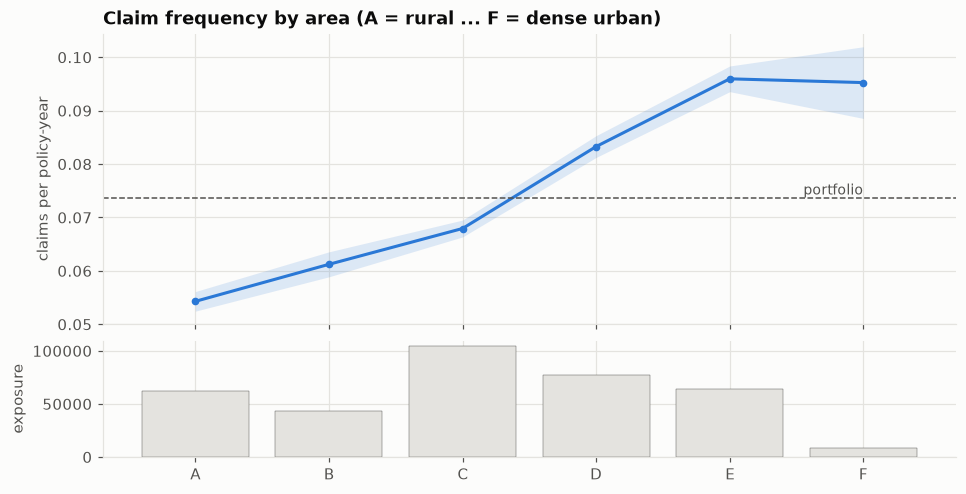

,exposure_share,frequency,relative_to_portfolio
Area,,,
A,0.1729,0.0543,0.7369
B,0.1200,0.0612,0.8310
C,0.2913,0.0679,0.9220
D,0.2151,0.0833,1.1303
E,0.1780,0.0960,1.3024
F,0.0227,0.0953,1.2928


In [7]:
t = one_way_frequency(df, "Area")
plot_one_way(t, "Claim frequency by area (A = rural ... F = dense urban)", name="02_freq_area")
t[["exposure_share", "frequency", "relative_to_portfolio"]]

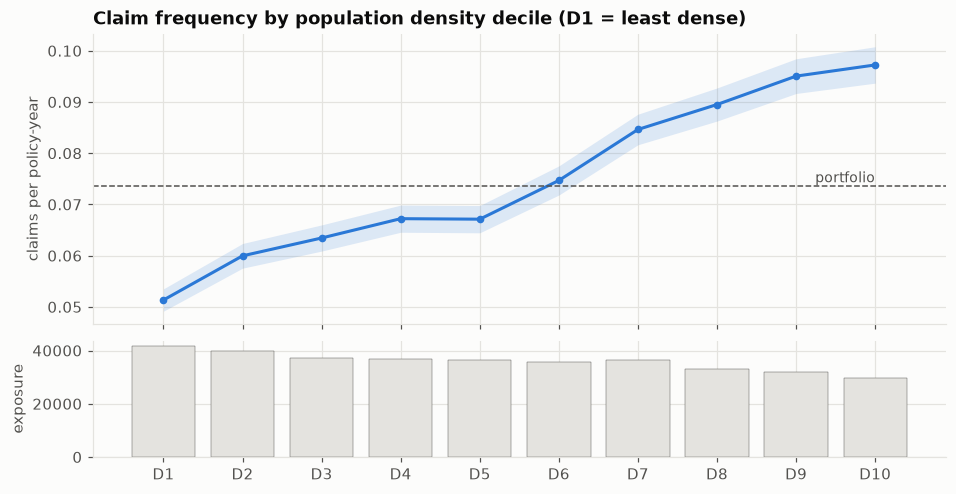

,density range,frequency,relative_to_portfolio
Density decile,,,
D1,"(0.999, 33.0]",0.0513,0.6968
D2,"(33.0, 67.0]",0.0600,0.8139
D3,"(67.0, 122.0]",0.0635,0.8611
D4,"(122.0, 214.0]",0.0672,0.9123
D5,"(214.0, 393.0]",0.0671,0.9110
D6,"(393.0, 716.0]",0.0747,1.0136
D7,"(716.0, 1313.0]",0.0846,1.1486
D8,"(1313.0, 2715.0]",0.0895,1.2147
D9,"(2715.0, 4128.0]",0.0950,1.2900


In [8]:
dens_labels = pd.qcut(df["Density"], 10).cat.categories
t = one_way_frequency(df, pd.qcut(df["Density"], 10, labels=[f"D{i}" for i in range(1, 11)]).rename("Density decile"))
plot_one_way(t, "Claim frequency by population density decile (D1 = least dense)", name="02_freq_density")
t["density range"] = [str(c) for c in dens_labels]
t[["density range", "frequency", "relative_to_portfolio"]]

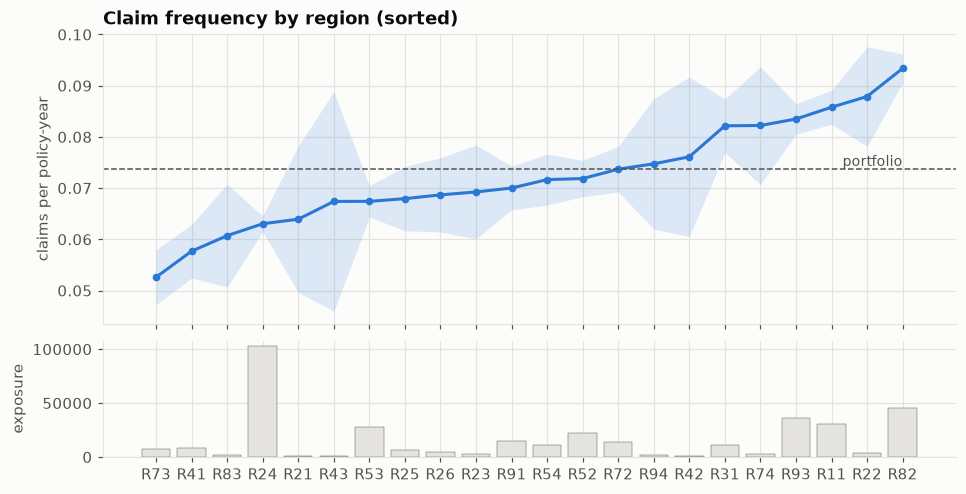

,exposure_share,claims,frequency,ci_low,ci_high
Region,,,,,
R73,0.0196,369,0.0526,0.0472,0.0580
R41,0.0226,468,0.0577,0.0525,0.0629
R83,0.0065,141,0.0607,0.0507,0.0707
R24,0.2866,6475,0.0630,0.0615,0.0646
R21,0.0034,77,0.0639,0.0497,0.0782
R43,0.0016,38,0.0674,0.0460,0.0888
R53,0.0774,1871,0.0674,0.0644,0.0705
R25,0.0186,452,0.0679,0.0617,0.0742
R26,0.0140,345,0.0687,0.0614,0.0759


In [9]:
t = one_way_frequency(df, "Region").sort_values("frequency")
plot_one_way(t, "Claim frequency by region (sorted)", name="02_freq_region")
t[["exposure_share", "claims", "frequency", "ci_low", "ci_high"]]

**What we see**

* **Area** and **Density** tell the same story: frequency increases steadily from rural (A, D1:
  ~0.70× the average) to urban (E-F, D9-D10: ~1.3×). Density deciles give a smooth, almost linear
  increase in *log* density.
* **Regions** range from 0.053 (R73) to 0.093 (R82), with tight confidence bands for the large
  regions. R24 alone holds 29% of the exposure (probably the insurer's home market) and has a low frequency.

**Mathematical meaning.** Frequency is close to linear in $\log(\text{Density})$ on the log scale, so the
GLM uses `log(Density)` as a single continuous term. Part of the regional differences is just
density (urban regions have more claims), part is genuinely regional (traffic, roads, climate,
local claim practices). Only a multivariate model can separate the two.

**Real-world meaning.** Cities have more traffic and more low-speed collisions: more claims.
For pricing, a city driver should pay more *for frequency* - we will check whether claims there are
also cheaper (section 2).

### 1.5 Vehicle brand and fuel

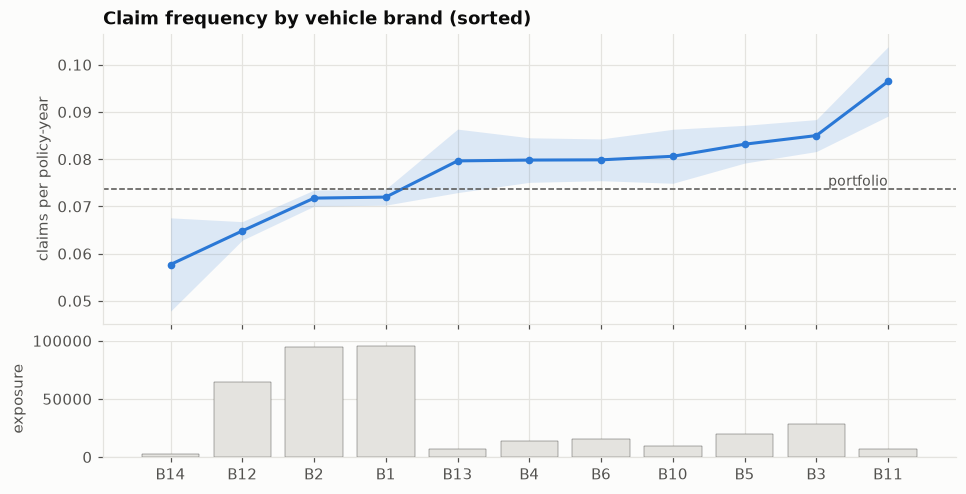

,exposure_share,frequency,relative_to_portfolio
VehBrand,,,
B14,0.0063,0.0577,0.7830
B12,0.1808,0.0648,0.8796
B2,0.2646,0.0718,0.9738
B1,0.2660,0.0720,0.9768
B13,0.0189,0.0796,1.0808
B4,0.0384,0.0798,1.0832
B6,0.0437,0.0799,1.0838
B10,0.0265,0.0806,1.0940
B5,0.0558,0.0832,1.1287


In [10]:
t = one_way_frequency(df, "VehBrand").sort_values("frequency")
plot_one_way(t, "Claim frequency by vehicle brand (sorted)", name="02_freq_brand")
t[["exposure_share", "frequency", "relative_to_portfolio"]]

In [11]:
t = one_way_frequency(df, "VehGas")
t[["exposure_share", "claims", "frequency", "ci_low", "ci_high", "relative_to_portfolio"]]

,exposure_share,claims,frequency,ci_low,ci_high,relative_to_portfolio
VehGas,,,,,,
Diesel,0.4760,13449,0.0788,0.0775,0.0802,1.0700
Regular,0.5240,12956,0.0690,0.0678,0.0702,0.9364


**What we see**

* **Brand**: from 0.78× (B14) and 0.88× (B12, 18% of exposure) up to 1.31× (B11). Brands are
  anonymised, so we cannot say which manufacturer is which.
* **Fuel**: diesel cars have a frequency of 0.079 vs 0.069 for petrol, **+14%**, with
  non-overlapping confidence intervals - a real difference, not noise.

**Real-world meaning.** Brand is a proxy for vehicle type and for the type of customer who buys it
(e.g. family cars, sport cars, company cars). Diesel cars are typically bought by people who drive
many kilometres per year (diesel was cheaper per km in France): more kilometres, more exposure to
accidents. We don't observe kilometres, so fuel type acts as a partial proxy for it.

## 2. Claim severity by rating factor

**Goal of this step:** check whether the *cost* of a claim depends on the same factors as its
*frequency*. We use the average **capped** cost (single claims capped at €100k, see notebook 01),
because with uncapped amounts a couple of multi-million claims would dominate every chart.

Severity is estimated on far fewer observations (~26k claims instead of ~680k policies), so the
confidence intervals are much wider: we expect weaker, noisier signals.

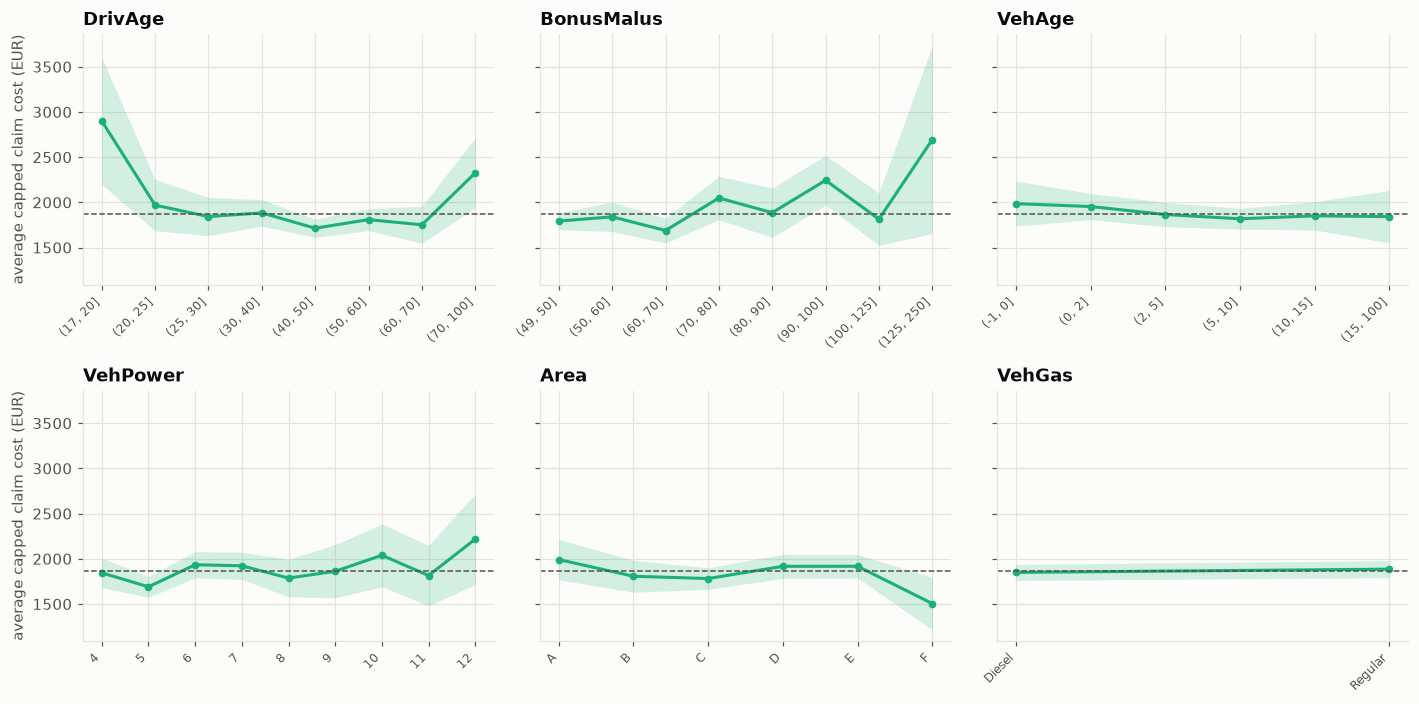

claims   avg_cost  relative_to_portfolio
DrivAge    (17, 20]       617 2,900.1903                 1.5533
           (20, 25]      1786 1,969.2130                 1.0547
           (25, 30]      2379 1,842.5702                 0.9868
           (30, 40]      5800 1,883.5131                 1.0088
           (40, 50]      6660 1,714.0688                 0.9180
           (50, 60]      5195 1,808.7751                 0.9687
           (60, 70]      2358 1,751.8324                 0.9382
           (70, 100]     1610 2,325.9677                 1.2457
BonusMalus (49, 50]     11553 1,792.7195                 0.9601
           (50, 60]      3576 1,840.0437                 0.9855
           (60, 70]      3116 1,688.4752                 0.9043
           (70, 80]      2798 2,048.2383                 1.0970
           (80, 90]      1720 1,885.6161                 1.0099
           (90, 100]     2386 2,243.5973                 1.2016
           (100, 125]    1093 1,814.2266                 0.9717
           (125, 250]     163 2,694.5999                 1.4432
VehAge     (-1, 0]       1181 1,985.5355                 1.0634
           (0, 2]        4566 1,953.7752                 1.0464
           (2, 5]        5344 1,865.4038                 0.9991
           (5, 10]       8008 1,818.2289                 0.9738
           (10, 15]      5642 1,850.8339                 0.9913
           (15, 100]     1664 1,841.8518                 0.9864
VehPower   4             3965 1,845.3630                 0.9883
           5             5115 1,690.1934                 0.9052
           6             6305 1,934.4477                 1.0360
           7             5592 1,922.9224                 1.0299
           8             1645 1,786.8891                 0.9570
           9             1220 1,862.0099                 0.9972
           10            1217 2,039.1266                 1.0921
           11             714 1,814.8645                 0.9720
           12             632 2,218.0417                 1.1879
Area       A             3364 1,991.4565                 1.0666
           B             2633 1,806.8393                 0.9677
           C             7093 1,781.8282                 0.9543
           D             6420 1,916.9050                 1.0266
           E             6121 1,917.2758                 1.0268
           F              774 1,504.9696                 0.8060
VehGas     Diesel       13449 1,849.2995                 0.9904
           Regular      12956 1,885.6875                 1.0099

In [12]:
sev_factors = {
    "DrivAge": pd.cut(df["DrivAge"], [17, 20, 25, 30, 40, 50, 60, 70, 100]),
    "BonusMalus": pd.cut(df["BonusMalus"], [49, 50, 60, 70, 80, 90, 100, 125, 250]),
    "VehAge": pd.cut(df["VehAge"], [-1, 0, 2, 5, 10, 15, 100]),
    "VehPower": df["VehPower"].clip(upper=12),
    "Area": df["Area"],
    "VehGas": df["VehGas"],
}
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey=True)
sev_tables = {}
for ax, (name, key) in zip(axes.ravel(), sev_factors.items()):
    t = one_way_severity(df, key.rename(name))
    sev_tables[name] = t
    x = np.arange(len(t))
    ax.fill_between(x, t["ci_low"], t["ci_high"], color=SERIES[2], alpha=0.18, lw=0)
    ax.plot(x, t["avg_cost"], color=SERIES[2], marker="o", ms=4)
    ax.axhline(PORTFOLIO_SEV, color=INK_2, ls="--", lw=1)
    ax.set_xticks(x); ax.set_xticklabels([str(i) for i in t.index], rotation=45, ha="right", fontsize=8)
    ax.set_title(name)
axes[0, 0].set_ylabel("average capped claim cost (EUR)"); axes[1, 0].set_ylabel("average capped claim cost (EUR)")
plt.tight_layout(); save(fig, "02_severity_one_way"); plt.show()
pd.concat({k: v[["claims", "avg_cost", "relative_to_portfolio"]] for k, v in sev_tables.items()})

**What we see**

* Severity is **much flatter** than frequency: most levels sit within ±10% of the average
  (€1,867) and the confidence bands are wide, often overlapping the average line.
* The clearest signal is **driver age**: claims caused by 18-20-year-olds cost ~1.55× the average,
  and by drivers over 70 ~1.25× (both with wide bands).
* **Area F** (densest urban) has *cheaper* claims (0.81×), the opposite of its frequency effect.
* Fuel type has **no** effect on severity (0.99× vs 1.01×).

**Mathematical meaning.** The signal-to-noise ratio of severity is low: the cost of a claim is
dominated by randomness (who you hit, how badly), and many claims are settled at a fixed
conventional amount. We should expect a severity model to explain only a *small* share of the
variance, and must regularise strongly to avoid fitting noise.

**Real-world meaning.** *How often* you crash depends a lot on who you are; *how much* the crash costs
much less. Young and elderly drivers cause more serious accidents (higher speeds and bodily injury
for the former, slower reactions and more fragile victims/drivers for the latter); city accidents
are frequent but at low speed, hence cheaper. A factor can push frequency and severity in opposite
directions - this is why the two are modelled separately.

## 3. Are the factors related to each other?

**Goal of this step:** detect factors that carry overlapping information. If two factors are
strongly related, (i) one-way charts of each one partly show the effect of the other, and (ii)
a GLM can struggle to split the effect between them (*multicollinearity*: unstable coefficients
with large standard errors).

* Between numeric/ordinal factors we use the **Spearman rank correlation** (it measures any
  *monotone* relation, not only linear, and is robust to skewed variables like Density).
* Between categorical factors we use **Cramér's V** (0 = independent, 1 = one determines the other),
  derived from the chi-square test of independence of the contingency table.

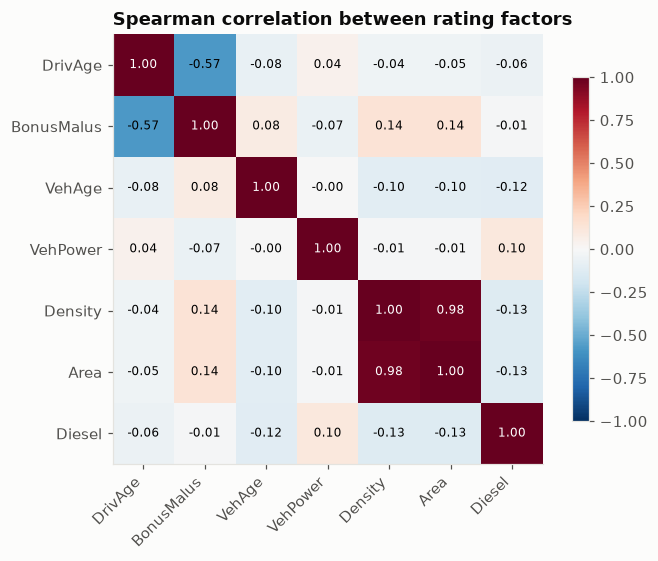

In [13]:
num = df[["DrivAge", "BonusMalus", "VehAge", "VehPower", "Density"]].assign(
    Area=df["Area"].cat.codes, Diesel=(df["VehGas"] == "Diesel").astype(int))
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
ax.grid(False); ax.set_title("Spearman correlation between rating factors")
fig.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); save(fig, "02_spearman"); plt.show()

In [14]:
cats = {"Area": df["Area"], "Region": df["Region"], "VehBrand": df["VehBrand"], "VehGas": df["VehGas"],
        "VehPower": df["VehPower"].astype(str)}
cv = pd.DataFrame(index=cats, columns=cats, dtype=float)
for a in cats:
    for b in cats:
        cv.loc[a, b] = 1.0 if a == b else cramers_v(cats[a], cats[b])
cv

,Area,Region,VehBrand,VehGas,VehPower
Area,1.0000,0.3195,0.0733,0.1314,0.0398
Region,0.3195,1.0000,0.1301,0.0944,0.0437
VehBrand,0.0733,0.1301,1.0000,0.1165,0.1576
VehGas,0.1314,0.0944,0.1165,1.0000,0.3187
VehPower,0.0398,0.0437,0.1576,0.3187,1.0000


**What we see**

* **Density and Area: ρ = 0.98.** `Area` is essentially a coarse binning of (log) density: the two
  carry the same information.
* **Driver age and bonus-malus: ρ = -0.57.** Older drivers have had more years to earn bonus.
* **Area and Region: Cramér's V = 0.32**, **fuel and vehicle power: V = 0.32** - moderate
  associations (regions differ in urbanisation; diesel engines are more common in some power classes).
* All other pairs are weakly related (|ρ| ≤ 0.14, V ≤ 0.16).

**Decision.** We **drop `Area`** from both models and keep the finer `Density` (log-transformed in
the GLM). Keeping two nearly identical variables in a GLM inflates the variance of both coefficients
(*multicollinearity*) without improving predictions, and would make the explanation of the tree
model (notebook 06) split the same effect arbitrarily between two variables.

### 3.1 A closer look: driver age vs bonus-malus

**Goal:** check how much of the "young drivers are risky" signal could actually be the bonus-malus
signal, since both are related by construction (everybody starts at 100 and earns bonus with years).

In [15]:
age_b = pd.cut(df["DrivAge"], [17, 20, 25, 30, 40, 50, 60, 70, 100])
print("average bonus-malus by driver age:")
print(df.groupby(age_b, observed=True)["BonusMalus"].mean().round(1).to_string())
bm_flag = np.where(df["BonusMalus"] <= 50, "BM = 50 (max bonus)", np.where(df["BonusMalus"] < 100, "BM 51-99", "BM >= 100"))
tab = df.groupby([age_b, bm_flag], observed=True).apply(
    lambda g: g["ClaimNb"].sum() / g["Exposure"].sum(), include_groups=False).unstack()
tab

average bonus-malus by driver age:
DrivAge
(17, 20]    95.3000
(20, 25]    87.6000
(25, 30]    73.9000
(30, 40]    61.2000
(40, 50]    55.1000
(50, 60]    53.7000
(60, 70]    53.0000
(70, 100]   52.4000


,BM 51-99,BM = 50 (max bonus),BM >= 100
DrivAge,,,
"(17, 20]",0.1374,0.1164,0.3982
"(20, 25]",0.0930,0.0927,0.2866
"(25, 30]",0.0745,0.0370,0.2160
"(30, 40]",0.0841,0.0433,0.2225
"(40, 50]",0.1238,0.0585,0.2339
"(50, 60]",0.1309,0.0536,0.2501
"(60, 70]",0.1451,0.0462,0.2313
"(70, 100]",0.1541,0.0446,0.3812


**What we see**

* The average BM drops from 95 at age 18-20 to ~53 above 50: the two factors are linked by construction.
* Yet **inside each BM group, age still matters**: among drivers at the maximum bonus (BM = 50), the
  18-20-year-olds have a frequency of 0.116 vs ~0.04-0.06 for drivers aged 25-70. And **inside each
  age group, BM still matters**: drivers with BM ≥ 100 have 3-5 times the frequency of those at BM = 50.
* The "BM 51-99" column *increases* with age above 40: an older driver who is *not* at the floor
  must have had recent claims, which is a stronger warning sign than for a young driver who simply
  had no time to earn bonus.

**Mathematical meaning.** Each factor has its own effect beyond the other, so both belong in the model;
and the effect of BM *depends on* age - an **interaction**. A main-effects GLM cannot capture it
unless we add an interaction term by hand; gradient boosting captures interactions automatically.
This is one of the main reasons why we expect the GBM to beat the GLM.

*Data quirk:* a BM of 50 at age 18-20 should be impossible under French rules (it takes ~13
claim-free years). It concerns little exposure; likely the BM of a parent's contract transferred to
a young driver, or a recording issue. We keep these rows (no reliable correction is possible).

## 4. Conclusions that guide the modelling

| Finding | Consequence for the models |
|---|---|
| Frequency is driven mostly by **bonus-malus**, **driver age** and **density**; region, brand and fuel matter moderately; vehicle power and age weakly | all factors are kept - the models will quantify each effect *jointly* |
| Driver age and vehicle age are **non-linear** | GLM: bins; GBM: raw values |
| Frequency is roughly **log-linear** in BM and in log(density) | GLM: continuous terms (BM capped at 150, log of density) |
| `Area` duplicates `Density` (ρ = 0.98) | drop `Area` |
| BM × age **interaction** | GBM should capture it; the GLM (main effects only) cannot - an expected source of GBM advantage |
| Severity varies little with the factors and is very noisy | expect low explanatory power; strong regularisation for the severity GBM |
| Some factors move frequency and severity in **opposite directions** (urban area) | model frequency and severity separately, then combine |

Next: **03 - Frequency modelling** (Poisson GLM vs LightGBM).